# Make Circles


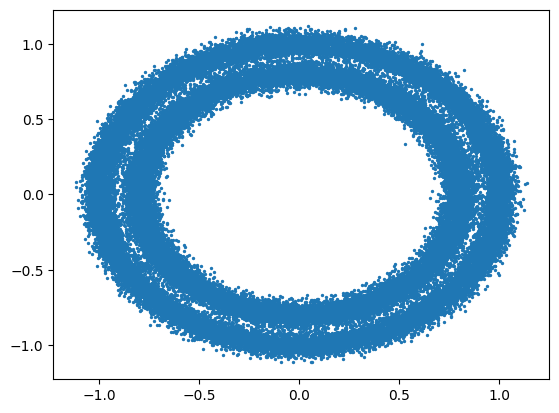

In [10]:
from sklearn.datasets import make_circles
import torch
from sklearn.model_selection import train_test_split
import matplotlib.pylab as plt
import numpy as np
from torch import nn


### Device agnostic code
def get_device(force_cpu=False):
    if force_cpu:
        return torch.device("cpu")
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    try:
        import torch_directml
        if torch_directml.device_count() > 0:
            return torch_directml.device()
    except ImportError:
        pass
    return torch.device("cpu") # GPU is not required on a dataset this small


device = get_device(force_cpu=True)

### Reproducibility
np.random.seed(42)
torch.manual_seed(42)



### Making the data (with seed 42 for reproducibility)
X, y = make_circles(n_samples=50000, shuffle=True, noise=0.04, random_state=42)

### Transforming to Tensors (Numpy -> Tensors)
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)


### Ploting the data
plt.scatter(X[:, 0], X[:, 1], s=2)


### Training and Testing split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, shuffle=True)

Epoch: 1 | Train Accuracy: 56.95% | Test Accuracy: 65.75% | Train Loss: 0.6822 | Test Loss: 0.6604
Epoch: 2 | Train Accuracy: 67.67% | Test Accuracy: 68.75% | Train Loss: 0.6244 | Test Loss: 0.5967
Epoch: 3 | Train Accuracy: 68.52% | Test Accuracy: 69.08% | Train Loss: 0.5920 | Test Loss: 0.5865
Epoch: 4 | Train Accuracy: 68.77% | Test Accuracy: 68.89% | Train Loss: 0.5882 | Test Loss: 0.5853
Epoch: 5 | Train Accuracy: 68.67% | Test Accuracy: 68.87% | Train Loss: 0.5877 | Test Loss: 0.5838
Epoch: 6 | Train Accuracy: 68.66% | Test Accuracy: 68.97% | Train Loss: 0.5872 | Test Loss: 0.5847
Epoch: 7 | Train Accuracy: 68.87% | Test Accuracy: 68.79% | Train Loss: 0.5871 | Test Loss: 0.5857
Epoch: 8 | Train Accuracy: 68.83% | Test Accuracy: 69.13% | Train Loss: 0.5872 | Test Loss: 0.5830
Epoch: 9 | Train Accuracy: 68.75% | Test Accuracy: 68.97% | Train Loss: 0.5874 | Test Loss: 0.5839
Epoch: 10 | Train Accuracy: 68.88% | Test Accuracy: 69.01% | Train Loss: 0.5867 | Test Loss: 0.5838
Epoch: 11

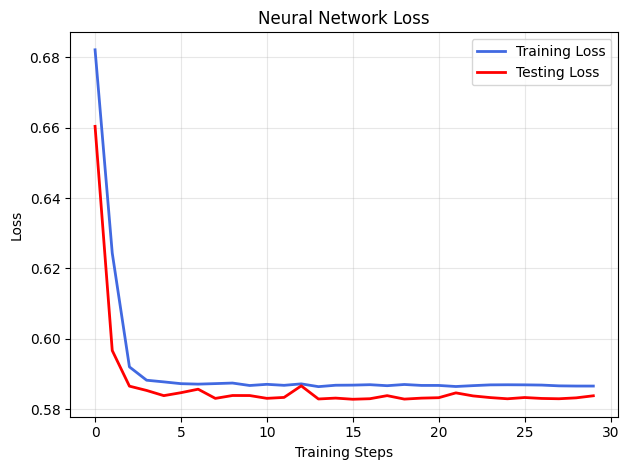

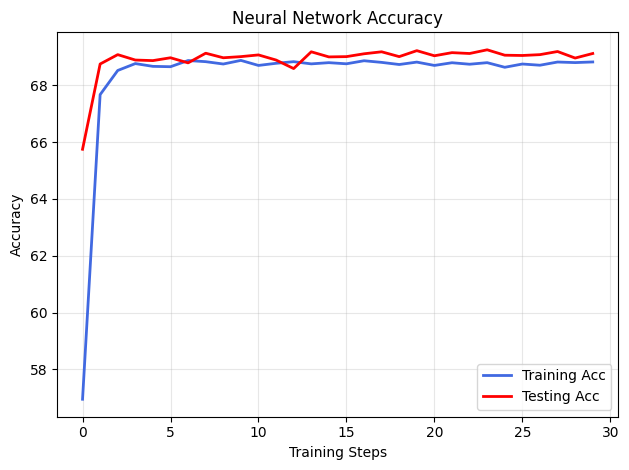

CPU times: user 1min 1s, sys: 272 ms, total: 1min 1s
Wall time: 10.4 s


In [ ]:
%%time


class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2, out_features=16)
        self.activation1 = nn.ReLU()

        self.layer2 = nn.Linear(in_features=16, out_features=16)
        self.activation2 = nn.ReLU()

        self.outputLayer = nn.Linear(in_features=16, out_features=1)
        self.outputActicatoin = nn.Softmax() # Not using this yet but will mby later
    def forward(self, x: torch.tensor):
        x = self.layer1(x)
        x = self.activation1(x)

        x = self.layer2(x)
        x = self.activation2(x)

        x = self.outputLayer(x)
        return x

def Sigmoid(logits: torch.tensor): 
    return (torch.sigmoid(logits) >= 0.5)








In [5]:
def BestHyperParam():
    pass